## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

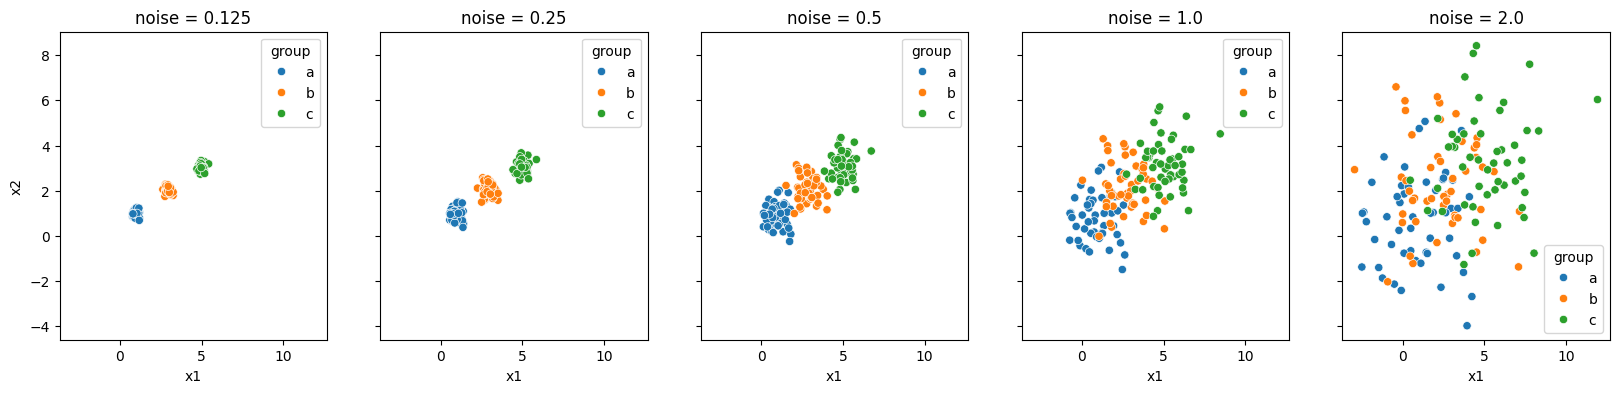

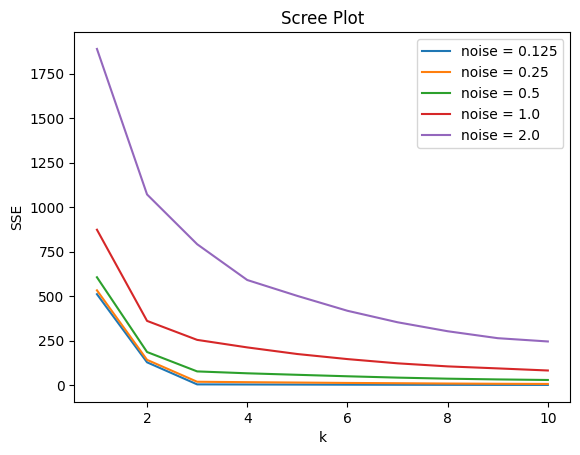

In [2]:
# Question 1

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

# Question 1.2

import seaborn as sns
import matplotlib.pyplot as plt

data = {"0.125": df0_125, "0.25": df0_25, "0.5": df0_5, "1.0": df1_0, "2.0": df2_0}

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
for ax, (noise, d) in zip(axes, data.items()):
    sns.scatterplot(data=d, x="x1", y="x2", hue="group", ax=ax).set(title=f"noise = {noise}")
plt.show()

# Question 1.3

from sklearn.cluster import KMeans

ks = np.arange(1, 11)
for noise, d in data.items():
    X = d[["x1", "x2"]]
    SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
    sns.lineplot(x=ks, y=SSE, label=f"noise = {noise}")
plt.title("Scree Plot")
plt.xlabel("k")
plt.ylabel("SSE")
plt.show()

Question 1.4:

k is essentially the place we want to stop adding clusters becasue adding more decreases SSE by much less. In this simulation there are 3 groups, so k = 3 is perfect becasue SSE falls quickly until 3 and then stops. As the noise rises, the groups start to overlap and each cluster keeps cutting SSE by a similar amount.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

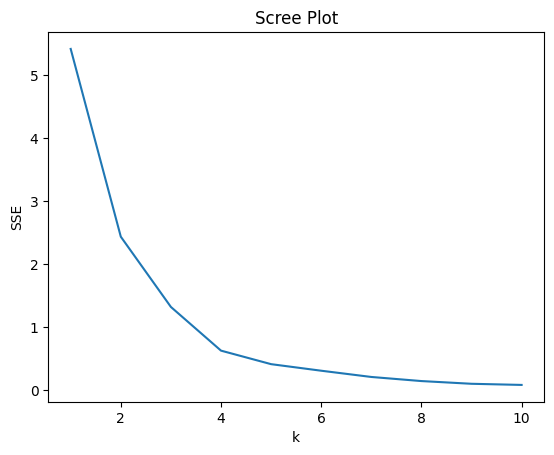

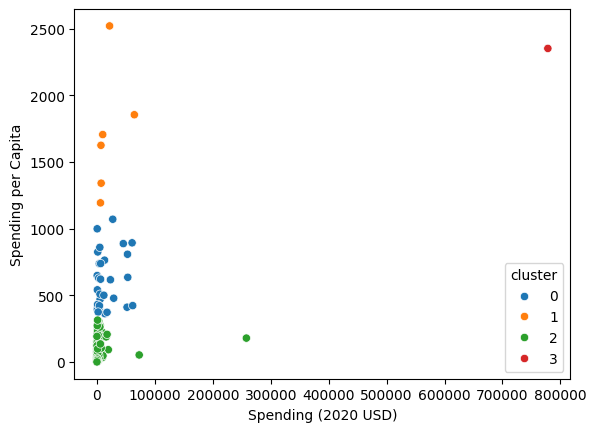

cluster                               0             1              2  \
Spending (2020 USD) count     30.000000      6.000000     111.000000   
                    mean   17077.591354  19443.362047    4859.185065   
                    std    20583.053357  22861.507114   25405.739131   
                    min      405.790494   6095.708713       8.622460   
                    25%     2294.039665   7023.251766     130.010211   
                    50%     5857.060906   8624.225729     382.464677   
                    75%    26296.001003  18857.070183    2297.032353   
                    max    61712.537169  64558.400000  257973.429834   
Spending per Capita count     30.000000      6.000000     111.000000   
                    mean     607.478618   1706.721916      80.061470   
                    std      206.928757    466.375705      83.501824   
                    min      362.467076   1193.598730       0.580129   
                    25%      422.208252   1412.083201      14.88

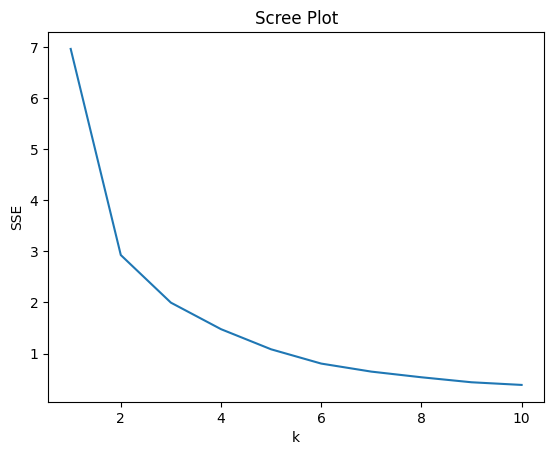

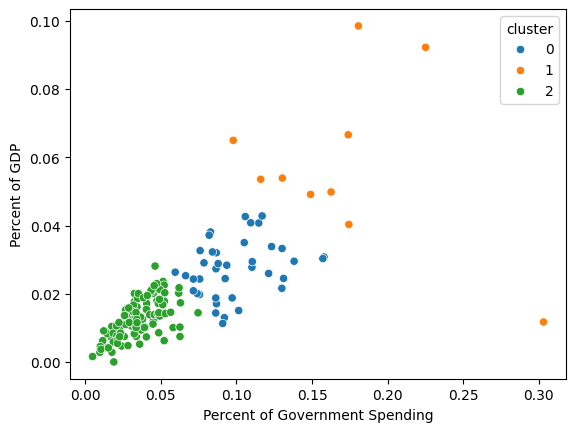

cluster                                       0          1          2
Percent of Government Spending count  39.000000  10.000000  99.000000
                               mean    0.098683   0.171289   0.035777
                               std     0.024125   0.058725   0.014549
                               min     0.059520   0.097882   0.004896
                               25%     0.082430   0.135010   0.025921
                               50%     0.092044   0.168248   0.034261
                               75%     0.112633   0.179081   0.047402
                               max     0.157918   0.303027   0.074624
Percent of GDP                 count  39.000000  10.000000  99.000000
                               mean    0.027412   0.058071   0.012664
                               std     0.008191   0.024867   0.005681
                               min     0.011317   0.011742   0.000054
                               25%     0.021254   0.049297   0.008393
                    

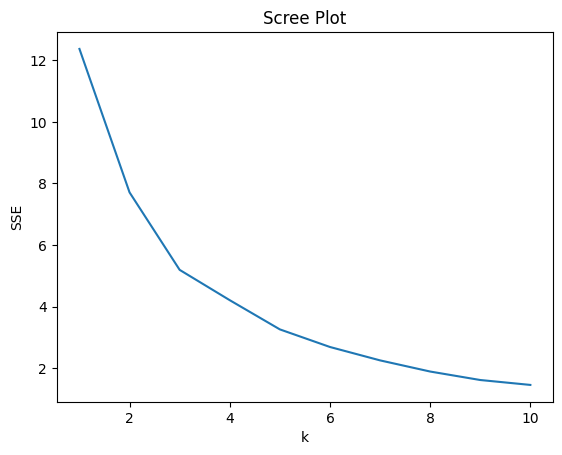

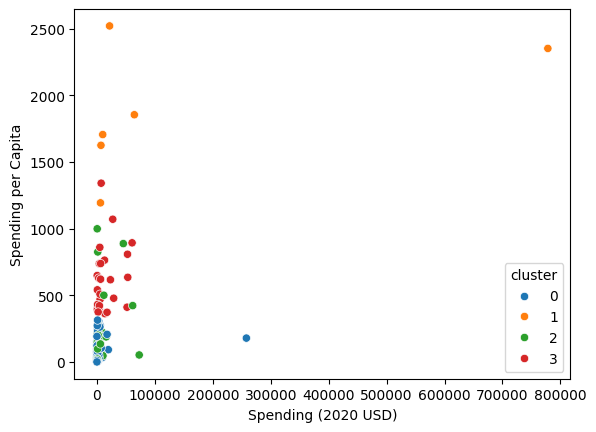

cluster                                           0              1  \
Spending (2020 USD)            count      86.000000       6.000000   
                               mean     4513.543790  147964.582042   
                               std     27841.230783  309635.189564   
                               min         8.622460    6095.708713   
                               25%        81.022976    7700.424616   
                               50%       288.061512   15897.570598   
                               75%      1138.618231   53872.942442   
                               max    257973.429834  778397.200000   
Spending per Capita            count      86.000000       6.000000   
                               mean       70.290644    1875.150751   
                               std        81.690590     489.800206   
                               min         0.580129    1193.598730   
                               25%        11.522275    1645.301864   
                    

In [4]:
# Question 2

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Question 1.1
df = pd.read_csv("SIPRI Military Expenditure Database.csv")
df = df[df["Year"] == 2020].dropna().copy()   # 148 rows

# Helper function to reduce repition in parts 2,3,4
def run(cols, k):
    X = (df[cols] - df[cols].min()) / (df[cols].max() - df[cols].min())

    # scree plot
    ks = np.arange(1, 11)
    SSE = [KMeans(n_clusters=i, n_init=10, random_state=0).fit(X).inertia_ for i in ks]
    sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
    plt.show()

    # cluster, scatter, describe
    df["cluster"] = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).labels_
    sns.scatterplot(data=df, x=cols[0], y=cols[1], hue="cluster", palette="tab10")
    plt.show()
    print(df.groupby("cluster")[cols].describe().T)
    print(df.loc[df["Country"] == "United States of America", "cluster"])

# Question 1.2
run(["Spending (2020 USD)", "Spending per Capita"], 4)

# Question 1.3
run(["Percent of Government Spending", "Percent of GDP"], 3)

# Question 1.4
run(["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"], 4)

---

Question 2 Response

1.1: No other cleaning is needed though there is some skew in the dataset.

1.2: The US is alone with 778 million total and $2,352 per capita, while cluster 1 has the highest per capita spending, cluster 0  holds large economies, and cluster 2 holds everyone else.

1.3: The US is in cluster 0 witg mean 9.9% of government spending and 2.7% of GDP, while cluster 1 is the high burden group  and cluster 2 is the low burden group.

1.4: The US is in cluster 1 with five other countries, and the rest split into lower spenders, high burden countries, and wealthy low burden countries.

1.5: Yes, it does isolate the US by size and separates high burden countries from low burden ones, and which countries group together changes depending on which variables you cluster on.

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Carter Shaffer

**Date:** 10/14/26

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]